In [1]:
import os
import sys
import warnings

sys.path.append("/path/to/GeneSPOT")
warnings.filterwarnings("ignore")

In [2]:
import itertools
import math
import pickle

import squidpy as sq
import seaborn as sns
import torch
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
from tqdm import tqdm
from pathlib import Path
from scipy.stats import pearsonr
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances, cosine_distances
from scipy import stats
from scipy.stats import pearsonr, spearmanr
from adjustText import adjust_text
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
from statannotations.Annotator import Annotator

matplotlib.rcParams['pdf.fonttype'] = 42

In [3]:
%load_ext autoreload
%autoreload 2

from genespot.utils import seed_everything

random_state = 42
seed_everything(random_state)

In [4]:
from palettable.cartocolors.diverging import Temps_7, Geyser_7, Tropic_7
from palettable.cartocolors.sequential import agSunset_7, BluYl_7, BurgYl_5, PurpOr_7, agGrnYl_7, agSunset_7_r, Magenta_7
from palettable.cmocean.sequential import Phase_20
from palettable.colorbrewer.diverging import Spectral_11_r, PRGn_11, PiYG_8_r, RdBu_11_r
from palettable.colorbrewer.sequential import PuRd_9, YlGnBu_9
from palettable.scientific.diverging import Vik_20, Berlin_20
from palettable.scientific.sequential import Batlow_20, Buda_20, Turku_20, Imola_20

In [5]:
DATA_DIR = Path('/path/to/GeneSPOT/data/spatial_aging_clocks')
RES_DIR = Path('/path/to/GeneSPOT/reproduce/fig5/res')
OUTPUTS_DIR = Path('/path/to/GeneSPOT/reproduce/fig5/outputs')
os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

In [6]:
def correlation_confidence_interval(r,n,ci=0.95):
    '''
    Given correlation (r), number of samples (n), and confidence interval (ci).
    Computes the confidence interval lower and upper bounds for r
    '''
    from scipy.stats import norm
    import math
    
    z = norm.ppf(1-(1-ci)/2)
    lower = math.tanh(math.atanh(r)-z/np.sqrt(n-3))
    upper = math.tanh(math.atanh(r)+z/np.sqrt(n-3))
    
    return((lower,upper))

In [7]:
adata = sc.read_h5ad(DATA_DIR / 'adata.h5ad')
adata.layers['counts'] = adata.X.copy()
adata.obs['age'] = adata.obs['age'].astype('category')
ages = [3.4, 3.8, 4.3, 5.4, 6.6, 9.8, 12.9, 15.5, 15.8, 18.8, 19.8, 21.4, 23.5, 24.6, 26.7, 28.5, 30.9, 32.6, 33.2, 34.5]
n_ages = len(ages)
regions = adata.obs['subregion'].cat.categories.tolist()

non_aging_degs = pd.read_csv(DATA_DIR / 'non_degs.csv', header=None).values.reshape(-1, ).tolist()
exclude_genes = ['Gfap', 'Crym', 'Drd2', 'Nr4a2', 'Ighm', 'Slc17a7', 'Aldoc', 'Adora2a', 'Cd4', 'C1ql3', 'Stmn2', 'Pvalb', 'Thbs4', 'Gja1', 'Atp1a2', 'C4b', 'Drd1', 'Lamp5', 'Slc1a2', 'Sparc', 'Map1lc3a', 'Tox', 'Penk', 'Gad2', 'Chat', 'Apoe', 'Aqp4', 'Sulf2', 'Sox9', 'Clu', 'Tubb3', 'Slc32a1', 'Aldh1l1', 'Spock2', 'Nfic', 'Olig1', 'Flt1', 'Pbx3', 'Pdgfra', 'Adamts3', 'Tac1', 'Cdh2', 'Slc1a3', 'Agpat3', 'Fgfr3', 'Msmo1', 'Ntm', 'Efnb2', 'Apod', 'Cd47', 'Gad1', 'Cdk5r1', 'Cfl1', 'Jak1', 'Sst', 'Sox2', 'Dpp6', 'Stub1', 'Igf2', 'Elovl5', 'Fads2', 'Trim2', 'Syt11', 'C1qa', 'Npy', 'Htt', 'Pcsk1n', 'Akt1', 'Csf1r', 'Igf1r', 'Sox11', 'Slc17a6', 'Mtor', 'C1qb', 'Sod2', 'Btg2', 'Gpm6b', 'Vcam1', 'Nr2e1', 'Parp1']
available_genes = list(sorted(set(adata.var_names) - set(exclude_genes)))
non_aging_degs = list(sorted(set(non_aging_degs) - set(exclude_genes)))
print(len(available_genes), len(non_aging_degs))

220 101


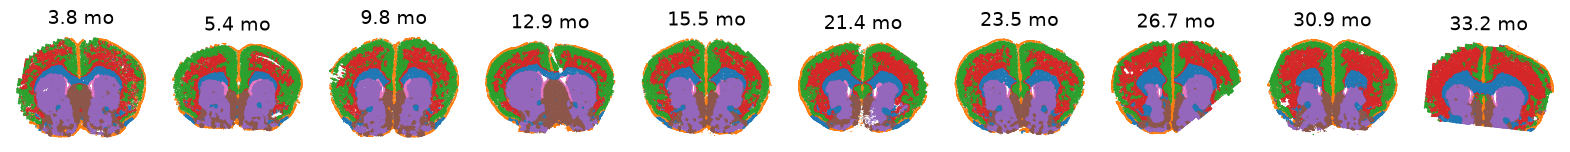

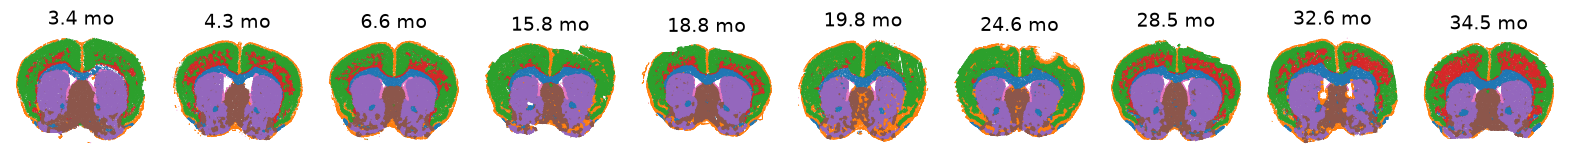

In [8]:
for batch in adata.obs['batch'].cat.categories:
    batch_adata = adata[adata.obs['batch'] == batch]
    fig, axs = plt.subplots(1, 10, figsize=(20, 7))
    batch_ages = sorted(batch_adata.obs['age'].unique())
    for i, age in enumerate(batch_ages):
        ax = axs[i]
        sub_adata = batch_adata[batch_adata.obs['age'] == age]
        sc.pl.embedding(
            sub_adata, 
            color='subregion',
            basis='spatial',
            ax=ax, 
            show=False,
            frameon=False,
            legend_loc=None
        )
        ax.set_aspect(1)
        ax.set_title(str(age)+" mo",fontsize=14)
        ax.xaxis.set_visible(False)
        plt.setp(ax.spines.values(), visible=False)
        ax.tick_params(left=False, labelleft=False)
        ax.patch.set_visible(False)
        ax.set_aspect(1)
    
    plt.subplots_adjust(wspace=0.1, hspace=-0.6)
    plt.show()

In [9]:
# available_genes = list(sorted(set(adata.var_names) - set(exclude_genes)))
available_genes = non_aging_degs
gdata_dict = dict()
gene2gene_sim_hvgs = dict()

agg_meth = 'mean'
landmarks = [f'SpatialLandmark_{ann}' for ann in regions]

for i, sample in enumerate(ages):
    # Intermediate results generated by GeneSPOT (such as `gdata` objects) can be accessed from our [Google Drive repository](https://drive.google.com/drive/folders/1hYBZrbvzJgx6OdpfvZqtf1Uz6ccriHVL?usp=sharing).
    gdata_dict[sample] = sc.read_h5ad(DATA_DIR / f'm{sample}_gdata_aggbymean_landmark.h5ad')
    gene2gene_sim = cosine_similarity(
        gdata_dict[sample][available_genes + landmarks].obsm['feature_embedding'],
        gdata_dict[sample][available_genes + landmarks].obsm['feature_embedding'],
    )
    gene2gene_sim = np.round(gene2gene_sim, 4)
    gene2gene_sim = pd.DataFrame(
        gene2gene_sim,
        index=available_genes + landmarks, 
        columns=available_genes + landmarks)
    gene2gene_sim_hvgs[sample] = gene2gene_sim

In [10]:
#### Non-aging-degs analysis
from scipy.stats import pearsonr, spearmanr, mannwhitneyu, ttest_ind, hypergeom

##### 1. Gene proximity trajectory analysis
gene2landmark = []
for age in ages:
    gene2landmark.append(
        gene2gene_sim_hvgs[age].loc[landmarks, non_aging_degs].values
    )

gene2landmark = np.stack(gene2landmark, axis=-1)
print('Gene2Landmark: ', gene2landmark.shape)

dgea_dict = {}
X = ages

for r, region in enumerate(regions):
    r_gene_by_age = gene2landmark[r, :, :]
    dgea_dict[region] = {}
    dgea_dict[region]['gene'] = []
    dgea_dict[region]['spearman'] = []
    dgea_dict[region]['p-value'] = []
    dgea_dict[region]['ci_95_low'] = []
    dgea_dict[region]['ci_95_high'] = []
    for g, gene in enumerate(non_aging_degs):
        Y = r_gene_by_age[g]
        spear = spearmanr(X,Y)
        ci95 = correlation_confidence_interval(spear[0],len(X),ci=0.95)
        
        # get results
        dgea_dict[region]['gene'].append(gene)
        dgea_dict[region]['spearman'].append(spear[0])
        dgea_dict[region]['p-value'].append(spear[1])
        dgea_dict[region]['ci_95_low'].append(ci95[0])
        dgea_dict[region]['ci_95_high'].append(ci95[1])

# save results as CSV
for ki, key in enumerate(dgea_dict.keys()):
    key_df = pd.DataFrame([])
    key_df['gene'] = dgea_dict[key]['gene']
    key_df[f'{key}_PValue'] = dgea_dict[key]['p-value']
    key_df[f'{key}_Spearman'] = dgea_dict[key]['spearman']
    key_df[f'{key}_Lower95CI'] = dgea_dict[key]['ci_95_low']
    key_df[f'{key}_Upper95CI'] = dgea_dict[key]['ci_95_high']
    
    if ki == 0:
        combined_df = key_df
    else:
        combined_df = pd.merge(combined_df,key_df,on='gene')
    
combined_df.to_csv(RES_DIR / 'subregion_dgea_spearman_genespot.csv', index=False)
combined_df = combined_df.set_index('gene')
expr_spearm = pd.read_csv(DATA_DIR / 'subregion_dgea_spearman_combinedbulked.csv', index_col=0)

Gene2Landmark:  (7, 101, 20)


In [11]:
pos_genes = dict()
neg_genes = dict()
num_pos = []
num_neg = []

for region in regions:
    coefs = np.array(dgea_dict[region]['spearman'])
    pvals = np.array(dgea_dict[region]['p-value'])
    lowbounds = np.array(dgea_dict[region]['ci_95_low'])
    hibounds = np.array(dgea_dict[region]['ci_95_high'])
    genes = np.array(dgea_dict[region]['gene'])
    
    pos_idx = (coefs>0.3)&(lowbounds>0)&(pvals<0.05)
    pos_genes[region] = genes[pos_idx].tolist()
    num_pos.append(np.sum(pos_idx))
    
    neg_idx = (coefs<-0.3)&(hibounds<0)&(pvals<0.05)
    neg_genes[region] = genes[neg_idx].tolist()
    num_neg.append(np.sum(neg_idx))

total_num = [num_pos[i]+num_neg[i] for i in range(len(regions))]
sorted_idx = np.argsort(total_num)
region_list = np.array(regions)[sorted_idx]
num_pos = np.array(num_pos)[sorted_idx]
num_neg = np.array(num_neg)[sorted_idx]

In [12]:
import pingouin as pg

df_neg = pd.DataFrame(columns=['Gene', 'Spearman', 'PValue', 'Lower95CI', 'Upper95CI', 'Metric', 'Region', 'Type'])
for region in region_list:
    selected_genes = neg_genes[region]
    if len(neg_genes[region]) > 0:
        expr_ = expr_spearm.loc[selected_genes, [f'{region}_Spearman', f'{region}_PValue', f'{region}_Lower95CI', f'{region}_Upper95CI']].reset_index()
        expr_.columns = ['Gene', 'Spearman', 'PValue', 'Lower95CI', 'Upper95CI']
        expr_['Metric'] = 'Expression level'
        prox_ = combined_df.loc[selected_genes, [f'{region}_Spearman', f'{region}_PValue', f'{region}_Lower95CI', f'{region}_Upper95CI']].reset_index()
        prox_.columns = ['Gene', 'Spearman', 'PValue', 'Lower95CI', 'Upper95CI']
        prox_['Metric'] = 'Proximity'
        df_ = pd.concat([expr_, prox_], axis=0)
        df_['Region'] = region
        df_['Type'] = 'Decreasing'
        df_neg = pd.concat([df_neg, df_])
df_neg['Spearman'] = df_neg['Spearman'].astype('float')

df_pos = pd.DataFrame(columns=['Gene', 'Spearman', 'PValue', 'Lower95CI', 'Upper95CI', 'Metric', 'Region', 'Type'])
for region in region_list:
    selected_genes = pos_genes[region]
    if len(selected_genes) > 0:
        expr_ = expr_spearm.loc[selected_genes, [f'{region}_Spearman', f'{region}_PValue', f'{region}_Lower95CI', f'{region}_Upper95CI']].reset_index()
        expr_.columns = ['Gene', 'Spearman', 'PValue', 'Lower95CI', 'Upper95CI']
        expr_['Metric'] = 'Expression level'
        prox_ = combined_df.loc[selected_genes, [f'{region}_Spearman', f'{region}_PValue', f'{region}_Lower95CI', f'{region}_Upper95CI']].reset_index()
        prox_.columns = ['Gene', 'Spearman', 'PValue', 'Lower95CI', 'Upper95CI']
        prox_['Metric'] = 'Proximity'
        df_ = pd.concat([expr_, prox_], axis=0)
        df_['Region'] = region
        df_['Type'] = 'Decreasing'
        df_pos = pd.concat([df_pos, df_])
df_pos['Spearman'] = df_pos['Spearman'].astype('float')

In [13]:
for region in region_list:
    region_neg = df_neg.loc[(df_neg['Region'] == region) & (df_neg['Metric'] == 'Proximity')]

    if region_neg.shape[0]>0:
        most_descrence = region_neg.iloc[region_neg['Spearman'].idxmin()]
        pval = most_descrence["PValue"]
        gene = most_descrence['Gene']
        spearm = most_descrence['Spearman']
        if pval < 0.001:
            psig = '***'
        elif pval < 0.01:
            psig = '**'
        elif pval < 0.05:
            psig = '*'
        else:
            psig = ''
        
        print(f'{gene} ({region}) {pval:.2e} {psig} {spearm:.2f}')
    
    # most_descrence = df_neg.loc[(df_neg['Region'] == region) & (df_neg['Metric'] == 'Proximity')].sort_values(by='Spearman').iloc[0]
    # print(f'{region}: {most_descrenceu["Spearman"]:.2f}[{most_descrenceu["Lower95CI"]:.2f}]')
    # break

Ccl5 (CTX_L1/MEN) 5.16e-03 ** -0.60
Slc6a3 (VEN) 3.47e-03 ** -0.62
Reln (STR_LS/NDB) 6.75e-04 *** -0.69
Cxcl1 (CTX_L4/5/6) 1.39e-03 ** -0.66
Mmp12 (CTX_L2/3) 4.20e-04 *** -0.71
Flt4 (STR_CP/ACB) 1.70e-03 ** -0.66


In [14]:
for region in region_list:
    region_pos = df_pos.loc[(df_pos['Region'] == region) & (df_pos['Metric'] == 'Proximity')]

    if region_pos.shape[0]>0:
        most_increase = region_pos.iloc[region_pos['Spearman'].idxmax()]
        pval = most_increase["PValue"]
        gene = most_increase['Gene']
        spearm = most_increase['Spearman']
        if pval < 0.001:
            psig = '***'
        elif pval < 0.01:
            psig = '**'
        elif pval < 0.05:
            psig = '*'
        else:
            psig = ''
        
        print(f'{gene} ({region}) {pval:.2e} {psig} {spearm:.2f}')
    
    # most_descrence = df_neg.loc[(df_neg['Region'] == region) & (df_neg['Metric'] == 'Proximity')].sort_values(by='Spearman').iloc[0]
    # print(f'{region}: {most_descrenceu["Spearman"]:.2f}[{most_descrenceu["Lower95CI"]:.2f}]')
    # break

Cd69 (CC/ACO) 1.79e-02 * 0.52
Trac (VEN) 7.67e-03 ** 0.58
Gapdh (CTX_L4/5/6) 6.50e-04 *** 0.70
Gapdh (CTX_L2/3) 2.20e-03 ** 0.64
Ccr4 (STR_CP/ACB) 6.92e-03 ** 0.58


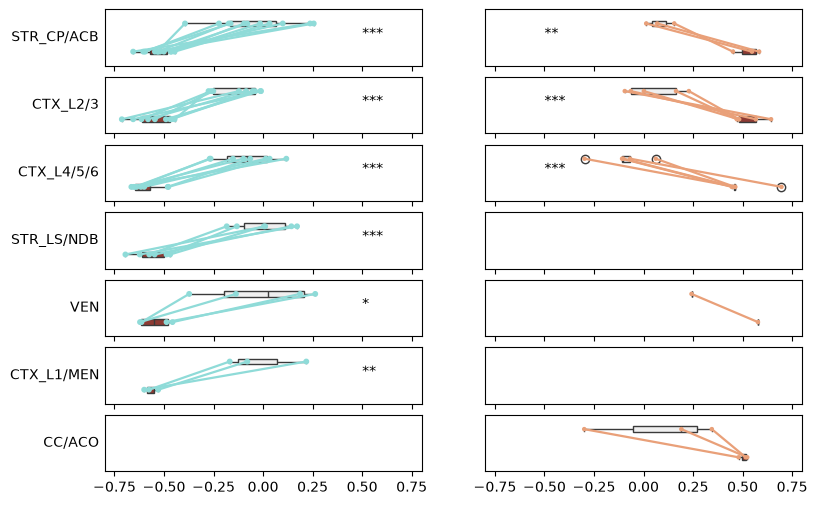

In [15]:
fig, axs = plt.subplots(7, 2, figsize=(9, 6), sharex=True)
for i, region in enumerate(region_list[::-1]):
    ax = axs[i,0]
    selected_genes = neg_genes[region]
    if len(selected_genes) > 0:
        df_neg_region = df_neg[df_neg['Region'] == region]
        pg.plot_paired(
            data=df_neg_region,
            dv='Spearman',
            within='Metric',
            subject='Gene',
            ax=ax, orient='h',
            order=['Proximity', 'Expression level'],
            colors=['#8fdbd8', '#cdcdcd', '#e9a079'],
            boxplot_kwargs={'hue': 'Metric', 'palette': {'Expression level': '#efefef', 'Proximity': '#9d2d24'}},
        )
        df_neg_region_expr = df_neg_region[df_neg_region['Metric'] == 'Expression level']
        df_neg_region_prox = df_neg_region[df_neg_region['Metric'] == 'Proximity']
        sig = stats.ttest_ind(df_neg_region_expr['Spearman'].values.reshape(-1, ), df_neg_region_prox['Spearman'].values.reshape(-1, ))
        if sig[1] < 0.001:
            ax.text(0.5, 0.5, '***')
        elif sig[1] < 0.01:
            ax.text(0.5, 0.5, '**')
        elif sig[1] < 0.05:
            ax.text(0.5, 0.5, '*')

    # ax.set_yticks([0, 1], ['Expression level', 'Proximity'])
    ax.set_ylabel(region, rotation=0, ha='right', va='center')
    ax.set_yticks([], [])
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(-0.5, 1.5)
    ax.set_xlabel('')

    ax = axs[i,1]
    selected_genes = pos_genes[region]
    if len(pos_genes[region]) > 0:
        df_pos_region = df_pos[df_pos['Region'] == region]
        
        pg.plot_paired(
            data=df_pos_region,
            dv='Spearman',
            within='Metric',
            subject='Gene',
            ax=ax, orient='h',
            order=['Proximity', 'Expression level'],
            colors=['#8fdbd8', '#cdcdcd', '#e9a079'],
            boxplot_kwargs={'hue': 'Metric', 'palette': {'Expression level': '#efefef', 'Proximity': '#9d2d24'}},
            pointplot_kwargs={'size': 10}
        )
        df_pos_region_expr = df_pos_region[df_pos_region['Metric'] == 'Expression level']
        df_pos_region_prox = df_pos_region[df_pos_region['Metric'] == 'Proximity']
        sig = stats.ttest_ind(df_pos_region_expr['Spearman'].values.reshape(-1, ), df_pos_region_prox['Spearman'].values.reshape(-1, ))
        if sig[1] < 0.001:
            ax.text(-0.5, 0.5, '***')
        elif sig[1] < 0.01:
            ax.text(-0.5, 0.5, '**')
        elif sig[1] < 0.05:
            ax.text(-0.5, 0.5, '*')

    # ax.set_yticks([0, 1], ['Expression level', 'Proximity'])
    ax.set_ylabel('')
    ax.set_yticks([], [])
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(-0.5, 1.5)
    ax.set_xlabel('')
plt.savefig(OUTPUTS_DIR / 'fig5b.eps', format='eps', dpi=300, bbox_inches='tight')    
plt.show()

In [16]:
from functools import reduce
all_neg_genes = list(set(reduce(lambda x, y: x + y, neg_genes.values())))
all_pos_genes = list(set(reduce(lambda x, y: x + y, pos_genes.values())))

In [17]:
print(len(all_pos_genes))
print('\n'.join(sorted(all_pos_genes)))

15
Alas2
Ccr4
Cd3e
Cd69
Cd9
Ctla4
Gapdh
Il6
Lsamp
Nmu
Rarres2
Sirt7
Son
Trac
Trp53


In [18]:
print(len(all_neg_genes))
print('\n'.join(all_neg_genes))

26
Fgf2
Ubd
Ikzf2
Pou5f1
Slc6a3
Nmu
Cd40
Cd19
Cd28
Cxcl1
Lars2
Il7r
Gdf15
Acta2
Ighd
Il10
Trac
Klf4
Ccl5
Mmp12
Reln
Alcam
AC149090.1
Hcrt
Pck1
Flt4


2026-08-06 05:14:01,776 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-08-06 05:14:02,643 [INFO] Done.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


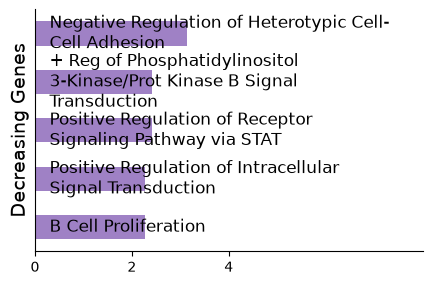

In [19]:
import gseapy as gp
import textwrap
gene_sets = [
    'GO_Biological_Process_2025',
]

enr = gp.enrichr(
    gene_list=all_neg_genes,
    gene_sets=gene_sets,
    outdir=None,
    verbose=True)
results = enr.results

ax = gp.barplot(
    results, 
    x='Adjusted P-value',
    cutoff=0.05,
    color='#7F57B2',
    figsize=(5, 8),
    top_term=5,
    title_fontsize=6,
    width=0.6
)
ax.set_xlabel('')
ax.set_yticklabels('')
ax.set_ylabel('Decreasing Genes', fontsize=14)
ax.set_xlim(0, 8)
ax.set_xticks([0, 2, 4], [0, 2, 4], fontsize=10)
ax.set_yticks([], [])

# 添加文本标签到 bar 的右侧
bars = ax.patches
max_width = 40
for bar, term in zip(bars, results['Term'][:len(bars)]):
    wrapped_term = '\n'.join(textwrap.wrap(term.split('(')[0], max_width))
    ax.text(
        0.3,
        bar.get_y() + bar.get_height() / 2,
        wrapped_term,
        va='center',
        ha='left',
        fontsize=12
    )

ax.set_aspect(1)
plt.savefig(OUTPUTS_DIR / 'fig5c2.eps', format='eps', dpi=300, bbox_inches='tight')    
plt.show()

2026-08-06 05:14:07,276 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-08-06 05:14:08,212 [INFO] Done.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


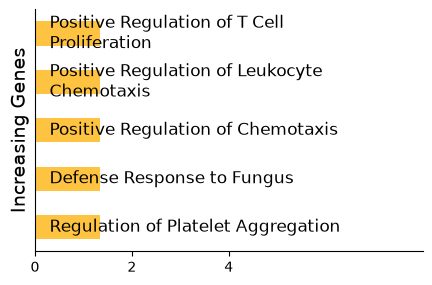

In [20]:
import gseapy as gp
import textwrap
gene_sets = [
    'GO_Biological_Process_2025',
]

enr = gp.enrichr(
    gene_list=all_pos_genes,
    gene_sets=gene_sets,
    outdir=None,
    verbose=True)
results = enr.results

ax = gp.barplot(
    results, 
    x='Adjusted P-value',
    cutoff=0.05,
    color='#FEAF00',
    figsize=(5, 8),
    top_term=5,
    title_fontsize=6,
    width=0.6
)
ax.set_xlabel('')
ax.set_yticklabels('')
ax.set_ylabel('Increasing Genes', fontsize=14)
ax.set_xlim(0, 8)
ax.set_xticks([0, 2, 4], [0, 2, 4], fontsize=10)
ax.set_yticks([], [])

# 添加文本标签到 bar 的右侧
bars = ax.patches
max_width = 40
for bar, term in zip(bars, results['Term'][:len(bars)]):
    wrapped_term = '\n'.join(textwrap.wrap(term.split('(')[0], max_width))
    ax.text(
        0.3,
        bar.get_y() + bar.get_height() / 2,
        wrapped_term,
        va='center',
        ha='left',
        fontsize=12
    )

ax.set_aspect(1)
plt.savefig(OUTPUTS_DIR / 'fig5c1.eps', format='eps', dpi=300, bbox_inches='tight')    
plt.show()

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.interpolate import make_interp_spline
from scipy.interpolate import splrep, BSpline
from scipy.signal import savgol_filter

In [22]:
##### 2. Gene-Gene pattern trajectory analysis

gene2gene = []
for age in ages:
    gene2gene.append(
        gene2gene_sim_hvgs[age].loc[available_genes, available_genes].values
    )
gene2gene = np.stack(gene2gene, axis=-1)
print('Gene2Gene: ', gene2gene.shape)
id2gene = pd.DataFrame(available_genes)
gene2id = id2gene.reset_index()
gene2id.columns = ['id', 'gene']
gene2id = gene2id.set_index('gene')

Gene2Gene:  (101, 101, 20)


In [23]:
ggbyage = []
ggpairs = []
gg_pattern = []
X = ages

for g1 in range(len(non_aging_degs)):
    g1name = non_aging_degs[g1]
    g1id = gene2id.loc[g1name].item()
    for g2 in range(g1):
        g2name = non_aging_degs[g2]
        g2id = gene2id.loc[g2name].item()
        
        ggpairs.append(f'{g1name}_{g2name}')
        
        Y = gene2gene[g1id, g2id, :]

        spear, pval = spearmanr(X, Y)
        
        ggbyage.append(Y)
        ci95 = correlation_confidence_interval(spear, len(X), ci=0.95)
        gg_pattern.append(
            (g1name, g2name, f'{g1name}_{g2name}', spear, pval, ci95[0], ci95[1])
        )

ggpairs = np.array(ggpairs)
ggbyage = np.stack(ggbyage)
ggbyage_df = pd.DataFrame(ggbyage, index=ggpairs, columns=ages)
gg_pattern = pd.DataFrame(gg_pattern, columns = ['G1', 'G2', 'GG', 'Spearman', 'PVal', 'CI95_low', 'CI95_high'])
# gg_pattern_sig = gg_pattern[gg_pattern['PVal'] < 0.05]
gg_pattern_sig = gg_pattern
ggbyage_df_sig = ggbyage_df.loc[gg_pattern_sig['GG'].values.tolist()]

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


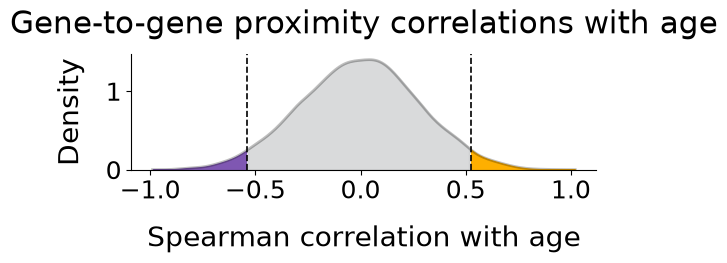

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(6, 1.5))

sns.kdeplot(
    data=gg_pattern,
    x='Spearman',
    ax=ax,
    fill=False,              # Fill the area under the curve
    color='black',     # Color for the line
    alpha=0.25,             # Transparency of the fill
    linewidth=2
)
corr_q025 = gg_pattern['Spearman'].quantile(0.025)
corr_q975 = gg_pattern['Spearman'].quantile(0.975)
line = ax.lines[0]
x_kde, y_kde = line.get_data()
mask = (x_kde >= corr_q025) & (x_kde <= corr_q975)
ax.fill_between(x_kde[mask], y_kde[mask], color='#c0c2c3', alpha=0.6, label='2.5th–97.5th percentile range')
mask_left = x_kde < corr_q025
ax.fill_between(x_kde[mask_left], y_kde[mask_left], color='#7F57B2', alpha=1)
mask_right = x_kde > corr_q975
ax.fill_between(x_kde[mask_right], y_kde[mask_right], color='#FEAF00', alpha=1)
ax.axvline(x=corr_q025, color='black', linestyle='--', linewidth=1.2)
ax.axvline(x=corr_q975, color='black', linestyle='--', linewidth=1.2)

# 4. Set titles, labels, and ticks
ax.set_title('Gene-to-gene proximity correlations with age', fontsize=22, pad=15)
ax.set_xlabel('Spearman correlation with age', fontsize=20, labelpad=15)
ax.set_ylabel('Density', fontsize=20, labelpad=15) # KDE plots show density on the y-axis
ax.tick_params(axis='both', which='major', labelsize=18)

# 5. Beautify the chart
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# 7. Adjust layout
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.savefig(OUTPUTS_DIR / 'fig5e.eps', format='eps', dpi=300, bbox_inches='tight')    
plt.show()

In [25]:
lower_than_ci_low = gg_pattern[(gg_pattern['Spearman'] < corr_q025) & (gg_pattern['PVal'] < 0.05)].sort_values(by='Spearman', ascending=True)
g1_spearman = lower_than_ci_low[['G1', 'Spearman']].rename(columns={'G1': 'Gene'})
g2_spearman = lower_than_ci_low[['G2', 'Spearman']].rename(columns={'G2': 'Gene'})
long_df = pd.concat([g1_spearman, g2_spearman], ignore_index=True)
avg_spearman_df = long_df.groupby('Gene')['Spearman'].mean().reset_index()
avg_spearman_df.rename(columns={'Spearman': 'Average_Spearman'}, inplace=True)
lsorted_avg_spearman_df = avg_spearman_df.sort_values(by='Average_Spearman', ascending=True)

greater_than_ci_high = gg_pattern[(gg_pattern['Spearman'] > corr_q975) & (gg_pattern['PVal'] < 0.05)].sort_values(by='Spearman', ascending=False)
g1_spearman = greater_than_ci_high[['G1', 'Spearman']].rename(columns={'G1': 'Gene'})
g2_spearman = greater_than_ci_high[['G2', 'Spearman']].rename(columns={'G2': 'Gene'})
long_df = pd.concat([g1_spearman, g2_spearman], ignore_index=True)
avg_spearman_df = long_df.groupby('Gene')['Spearman'].mean().reset_index()
avg_spearman_df.rename(columns={'Spearman': 'Average_Spearman'}, inplace=True)
usorted_avg_spearman_df = avg_spearman_df.sort_values(by='Average_Spearman', ascending=True)
print(len(lower_than_ci_low), len(lsorted_avg_spearman_df))
print(len(greater_than_ci_high), len(usorted_avg_spearman_df))

126 68
125 75


In [26]:
cnt = 0

for g1, g2, gg, spearm, pval, ci95low, ci95high in lower_than_ci_low.values:
    if cnt < 5:
        if pval < 0.001:
            psig = '***'
        elif pval < 0.01:
            psig = '**'
        elif pval < 0.05:
            psig = '*'
        else:
            psig = ''
        cnt += 1
        print(f'{g1}-{g2}: {spearm:.2f}{psig}')

Trp53-Ifng: -0.84***
Tigit-Insr: -0.83***
Pou5f1-Cd69: -0.82***
Sirt6-Cxcl1: -0.82***
Insr-Cd69: -0.81***


In [27]:
cnt = 0
for g1, g2, gg, spearm, pval, ci95low, ci95high in greater_than_ci_high.values:
    if cnt < 5:
        if pval < 0.001:
            psig = '***'
        elif pval < 0.01:
            psig = '**'
        elif pval < 0.05:
            psig = '*'
        else:
            psig = ''
        cnt += 1
        print(f'{g1}-{g2}: {spearm:.2f}{psig}')

Trp53-Gdf15: 0.87***
Insr-Gdf15: 0.86***
Ifng-Acta2: 0.80***
Pck1-Insr: 0.78***
Tph2-AC149090.1: 0.77***


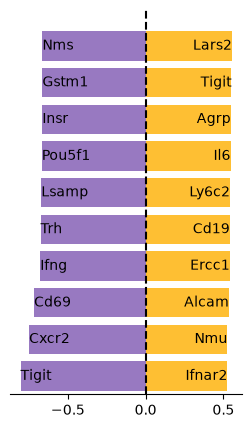

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(3, 5))
ax.barh(np.arange(10), usorted_avg_spearman_df.iloc[:10]['Average_Spearman'].values, color='#FEAF00', label="Increasing", alpha=0.8)
for i, (g, sp) in enumerate(usorted_avg_spearman_df.iloc[:10].values):
    ax.text(
        x=sp,
        y=i,
        s=g,
        ha='right',
        va='center'
    )

ax.barh(np.arange(10), lsorted_avg_spearman_df.iloc[:10]['Average_Spearman'].values, color='#7F57B2', label="Decreasing", alpha=0.8)
for i, (g, sp) in enumerate(lsorted_avg_spearman_df.iloc[:10].values):
    ax.text(
        x=sp,
        y=i,
        s=g,
        ha='left',
        va='center'
    )

ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_yticks([], [])
ax.set_ylim(-0.5, 10)
ax.vlines(0, -0.5, 10, 'black', '--')

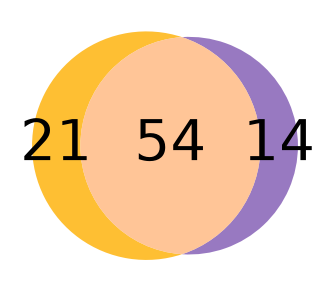

In [29]:
from matplotlib_venn import venn2

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ugenes = set(usorted_avg_spearman_df['Gene'].values.tolist())
lgenes = set(lsorted_avg_spearman_df['Gene'].values.tolist())
venn = venn2(
    subsets=[ugenes, lgenes],
    set_labels = ['', ''],
    set_colors=('#FEAF00', '#7F57B2'),
    alpha=0.8,
    normalize_to=1,
    ax=ax
)
venn.get_label_by_id('10').set_fontsize(40)
venn.get_label_by_id('11').set_fontsize(40)
venn.get_label_by_id('01').set_fontsize(40)

2026-08-06 05:14:21,778 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-08-06 05:14:22,854 [INFO] Done.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


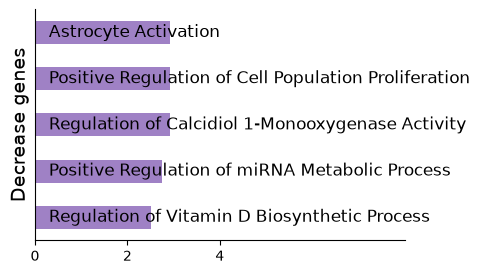

In [30]:
import gseapy as gp
import textwrap
gene_sets = [
    'GO_Biological_Process_2025',
]

enr = gp.enrichr(
    gene_list=list(lgenes-ugenes),
    gene_sets=gene_sets,
    organism='mouse',
    outdir=None,
    verbose=True)
results = enr.results

ax = gp.barplot(
    results, 
    x='Adjusted P-value',
    cutoff=0.05,
    color='#7F57B2',
    figsize=(7, 3),
    top_term=5,
    title_fontsize=6,
    width=0.6
)
ax.set_xlabel('')
ax.set_yticklabels('')
ax.set_ylabel('Decrease genes', fontsize=14)
ax.set_xlim(0, 8)
ax.set_xticks([0, 2, 4], [0, 2, 4], fontsize=10)
ax.set_yticks([], [])

# 添加文本标签到 bar 的右侧
bars = ax.patches
max_width = 60
for bar, term in zip(bars, results['Term'][:len(bars)]):
    wrapped_term = '\n'.join(textwrap.wrap(term.split('(')[0], max_width))
    ax.text(
        0.3,
        bar.get_y() + bar.get_height() / 2,
        wrapped_term,
        va='center',
        ha='left',
        fontsize=12
    )

ax.set_aspect(1)
plt.savefig(OUTPUTS_DIR / 'fig5f1.eps', format='eps', dpi=300, bbox_inches='tight')    

plt.show()

2026-08-06 05:14:27,385 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-08-06 05:14:28,332 [INFO] Done.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


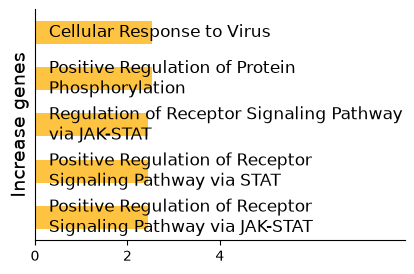

In [31]:
import gseapy as gp
import textwrap
gene_sets = [
    'GO_Biological_Process_2025',
]

enr = gp.enrichr(
    gene_list=list(ugenes-lgenes),
    gene_sets=gene_sets,
    organism='mouse',
    outdir=None,
    verbose=True)
results = enr.results

ax = gp.barplot(
    results, 
    x='Adjusted P-value',
    cutoff=0.05,
    color='#FEAF00',
    figsize=(7, 3),
    top_term=5,
    title_fontsize=6,
    width=0.6
)
ax.set_xlabel('')
ax.set_yticklabels('')
ax.set_ylabel('Increase genes', fontsize=14)
ax.set_xlim(0, 8)
ax.set_xticks([0, 2, 4], [0, 2, 4], fontsize=10)
ax.set_yticks([], [])

# 添加文本标签到 bar 的右侧
bars = ax.patches
max_width = 40
for bar, term in zip(bars, results['Term'][:len(bars)]):
    wrapped_term = '\n'.join(textwrap.wrap(term.split('(')[0], max_width))
    ax.text(
        0.3,
        bar.get_y() + bar.get_height() / 2,
        wrapped_term,
        va='center',
        ha='left',
        fontsize=12
    )

ax.set_aspect(1)
plt.savefig(OUTPUTS_DIR / 'fig5f2.eps', format='eps', dpi=300, bbox_inches='tight')    

plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


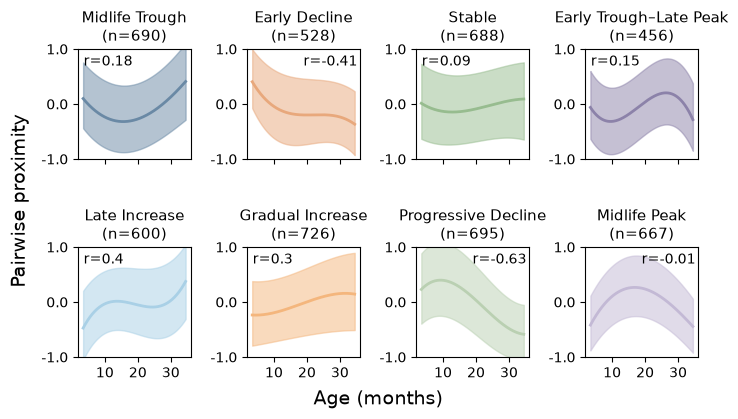

In [32]:
age_ggproximity_matrix = ggbyage_df_sig.values
age_ggproximity_matrix = StandardScaler().fit_transform(age_ggproximity_matrix.T)
age_ggproximity_matrix = age_ggproximity_matrix.T

n_clusters = 8
kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init='auto').fit(age_ggproximity_matrix)
gg_pattern_sig['cluster'] = kmeans.labels_
n_cols = 4
should_add_row = not (n_clusters % n_cols == 0)
n_rows = n_clusters // n_cols if not should_add_row else (n_clusters // n_cols) + 1

pos_dict = {
    "br": (0.5, 0.05),
    "bl": (0.05, 0.05),
    "tr": (0.5, 0.85),
    "tl": (0.05, 0.85)
}
ages_fine = np.linspace(np.min(ages), np.max(ages), 100)
fig = plt.figure(figsize=(2*n_cols, 2*n_rows))

plot_trajector_order = range(n_clusters)
group_names = [
    # 'Early Peak', 'Steady Decline', 'Early-Mid Peak', 'Early Trough', 
    # 'Consistent', 'Middle Trough', 'Early Increase', 'Slight Increase'
    'Midlife Trough', 'Early Decline', 'Stable', 'Early Trough–Late Peak',
    'Late Increase', 'Gradual Increase', 'Progressive Decline', 'Midlife Peak'
]

corner_for_annot = [
    "tl", "tr", "tl", 'tl',
    'tl', 'tl', 'tr', 'tr'
]

colors = [
    "#6A89A5", "#E8A87C", "#97BC8F", "#8C82A9",
    "#A9D0E6", "#F4B67D", "#BAD0B2", "#C3B9D5"
]

for i in range(n_rows):
    for j in range(n_cols):
        cid = (i * n_cols) + j
        if cid < n_clusters:
            ax = fig.add_subplot(n_rows, n_cols, cid+1)

            # subset into cluster
            sub_age_expn_matrix = age_ggproximity_matrix[kmeans.labels_==cid,:]
            
            # compute mean and spread for each cluster
            median_expn = np.median(sub_age_expn_matrix,axis=0)
            spread_expn_upper = np.percentile(sub_age_expn_matrix,75,axis=0)
            spread_expn_lower = np.percentile(sub_age_expn_matrix,25,axis=0)
            
            # smoothen mean trajectories
            ages_fine = np.linspace(np.min(ages), np.max(ages), 500)
            
            smoother = BSpline(*splrep(ages, median_expn, s=len(ages)))
            median_expn_smooth = smoother(ages_fine)
            
            smoother = BSpline(*splrep(ages, spread_expn_upper, s=len(ages)))
            spread_expn_upper_smooth= smoother(ages_fine)
            
            smoother = BSpline(*splrep(ages, spread_expn_lower, s=len(ages)))
            spread_expn_lower_smooth= smoother(ages_fine)
            
            r,p = pearsonr(ages, median_expn)
            if cid < len(corner_for_annot):
                x, y1 = pos_dict[corner_for_annot[j+i*n_cols]]
                ax.text(x, y1, "r="+str(round(r,2)), transform=ax.transAxes, size=10)
            
            ax.plot(ages_fine, median_expn_smooth, color=colors[cid] if cid < len(colors) else 'grey', linewidth=2)
            ax.fill_between(ages_fine, spread_expn_lower_smooth, spread_expn_upper_smooth, 
                            alpha=0.5, color=colors[cid] if cid < len(colors) else 'grey')
            if i == n_rows - 1:
                ax.set_xticks([10, 20, 30], [10, 20, 30], rotation=0)
            else:
                ax.set_xticks([10, 20, 30], [])
            ax.set_yticks([-1, 0, 1], [-1.0, 0., 1.0])
            title = f'{group_names[cid] if cid < len(group_names) else ""}\n(n={sub_age_expn_matrix.shape[0]})'
            ax.set_title(title, size=11)
            ax.set_ylim(-1, 1)

            ax.tick_params(axis='both', which='major', labelsize=10)
            ax.tick_params(axis='both', which='minor', labelsize=10)

fig.supxlabel("Age (months)", fontsize=14, y=-0.02)
fig.supylabel("Pairwise proximity", fontsize=14, x=0.04)
plt.subplots_adjust(wspace=0.5, hspace=0.8)
plt.savefig(OUTPUTS_DIR / 'fig5g.eps', format='eps', dpi=300, bbox_inches='tight')    

plt.show()

In [33]:
import gseapy as gp
import textwrap

gene_sets = ['GO_Biological_Process_2025']
pattern_go_results = {}
pattern_pair_counts = {}
pattern_gene_counts = {}

# Figure 5G uses all pairwise trajectories. For Figure 5H, enrichment is
# performed on genes from nominally age-associated pairs within each pattern.
for g in range(n_clusters):
    pattern_pairs = gg_pattern_sig.loc[
        (gg_pattern_sig['PVal'] < 0.05) & 
        (gg_pattern_sig['cluster'] == g)
    ].copy()
    pattern_genes = sorted(set(pattern_pairs['G1']) | set(pattern_pairs['G2']))
    pattern_pair_counts[g] = len(pattern_pairs)
    pattern_gene_counts[g] = len(pattern_genes)
    print(
        f'{group_names[g]}: {len(pattern_pairs)} age-associated pairs, '
        f'{len(pattern_genes)} genes'
    )

    enr = gp.enrichr(
        gene_list=pattern_genes,
        gene_sets=gene_sets,
        organism='mouse',
        outdir=None,
        no_plot=True,
        verbose=True,
    )
    pattern_go_results[g] = enr.results.copy()
    pattern_pairs.to_csv(
        RES_DIR / f'fig5H_pattern_{g + 1}_age_associated_pairs.csv',
        index=False,
    )
    pattern_go_results[g].to_csv(
        RES_DIR / f'fig5H_pattern_{g + 1}_GO.csv',
        index=False,
    )

top_terms = {}
for g, results in pattern_go_results.items():
    shown = (
        results.loc[results['Adjusted P-value'] < 0.05]
        .sort_values('Adjusted P-value')
        .head(5)
        .copy()
    )
    shown['-log10_adjusted_P'] = -np.log10(
        shown['Adjusted P-value'].clip(lower=np.finfo(float).tiny)
    )
    top_terms[g] = shown

plot_values = [
    frame['-log10_adjusted_P']
    for frame in top_terms.values()
    if not frame.empty
]
if not plot_values:
    raise ValueError('No GO terms passed the adjusted P < 0.05 threshold.')

Midlife Trough: 51 age-associated pairs, 54 genes


2026-08-06 05:14:38,462 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-08-06 05:14:39,570 [INFO] Done.


Early Decline: 63 age-associated pairs, 62 genes


2026-08-06 05:14:41,085 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-08-06 05:14:42,262 [INFO] Done.


Stable: 53 age-associated pairs, 59 genes


2026-08-06 05:14:43,928 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-08-06 05:14:45,124 [INFO] Done.


... (6 outputs left out)

Progressive Decline: 180 age-associated pairs, 84 genes


2026-08-06 05:14:55,822 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-08-06 05:14:57,388 [INFO] Done.


Midlife Peak: 24 age-associated pairs, 35 genes


2026-08-06 05:14:58,969 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-08-06 05:14:59,933 [INFO] Done.


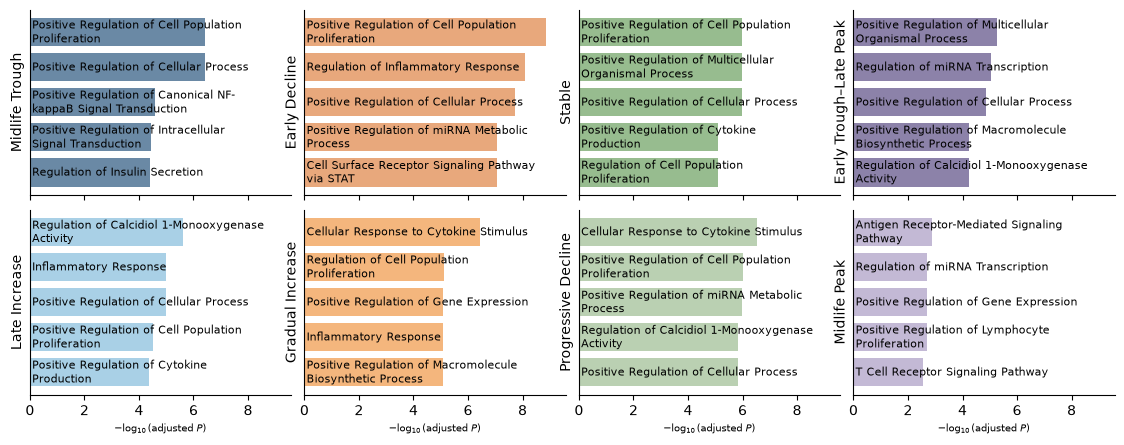

In [34]:
xmax = max(2, pd.concat(plot_values).max() * 1.08)
fig, axs = plt.subplots(2, 4, figsize=(14, 5), sharex=True)

for g, ax in enumerate(axs.ravel()):
    shown = top_terms[g].sort_values('Adjusted P-value')
    y = np.arange(len(shown))
    ax.barh(y, shown['-log10_adjusted_P'], color=colors[g])
    ax.set_yticks([])
    ax.invert_yaxis()
    ax.set_xlim(0, xmax)
    ax.set_ylabel(group_names[g], fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', labelsize=10)

    for row_id, (_, row) in enumerate(shown.iterrows()):
        term = row['Term'].split('(')[0].strip()
        wrapped_term = '\n'.join(textwrap.wrap(term, width=40))
        ax.text(0.08, row_id, wrapped_term, va='center', ha='left', fontsize=8)

    if shown.empty:
        ax.text(
            0.5, 0.5, 'No terms with adjusted P < 0.05',
            transform=ax.transAxes, ha='center', va='center', fontsize=6,
        )
    if g >= 4:
        ax.set_xlabel(r'$-\log_{10}$(adjusted $P$)', fontsize=7)

plt.subplots_adjust(wspace=0.05, hspace=0.08)
plt.savefig(OUTPUTS_DIR / 'fig5h.eps', format='eps', dpi=300, bbox_inches='tight')    
plt.show()